# Annotate PPI scores with ClinVar annotations

In [27]:
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [28]:
sqy2h_outputs_dir = "../3_outputs/sqY2H"
metadata_outputs_dir = "../../../1_allele_collection/3_outputs"
integrative_inputs = "../../../3_integrated_assay_results/1_inputs"

In [29]:
# process metadata
metadata = pl.DataFrame(pd.read_csv(f"{metadata_outputs_dir}/varchamp_seq_confirm_alleles_clinvar_gnomad.tsv", sep="\t"))
mut_cols = ["mutation_id_rc4", "mutation_id_cegs2", "mutation_id_edgotyping3"]
id_vars = [col for col in metadata.columns if col not in mut_cols]
# metadata = metadata.unpivot(index=id_vars, 
#                             on=mut_cols,
#                             variable_name="mutation_collection",
#                             value_name="mut_id")

priority_col = ["orf_id", "mut_id", "symbol", "aa_change", "ensembl_gene_id", "clinvar_clnsig_clean", "gnomad_af", "StarStatus"]
metadata = metadata.select(priority_col).filter(~pl.col("mut_id").is_null()).with_columns(
    pl.col("mut_id").cast(pl.Int64).alias("mut_id"),
    pl.col("orf_id").cast(pl.Int64).alias("orf_id")
)

In [30]:
# merge scores with metadata
scores = pl.read_csv(f"{sqy2h_outputs_dir}/5_variant_perturbation_scores_automated_summed.csv").with_columns(
    pl.col("db_orf_id").cast(pl.Int64).alias("orf_id"),
    pl.col("db_mut_id").cast(pl.Int64).alias("mut_id"),
).drop(["db_orf_id", "db_mut_id"])

scores = scores.join(metadata, on=["orf_id", "mut_id"])
# scores.write_csv(f"{sqy2h_outputs_dir}/6_variant_perturbation_scores_annotated.csv")
# scores.write_csv(f"{integrative_inputs}/ppi_scores.csv")
scores = scores.filter(pl.col("clinvar_clnsig_clean") != "5_Others")

In [31]:
scores = scores.with_columns(
    (pl.col("normalized_euclid_distance") / scores["normalized_euclid_distance"].max()).alias("normalized_euclid_distance_normalized")
)

In [32]:
scores_pd = scores.to_pandas()
print(scores_pd['clinvar_clnsig_clean'].value_counts())

clinvar_clnsig_clean
1_Pathogenic     281
4_VUS             89
3_Conflicting     83
2_Benign          33
Name: count, dtype: int64


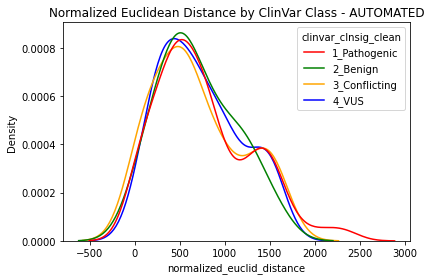

In [33]:
variables = ["normalized_euclid_distance", "frac_per_0.0", "frac_per_0.2", "cosine_distance"]

# Define color mapping for classes
color_map = {
    "1_Pathogenic": "red",
    "2_Benign": "green",
    "3_Conflicting": "orange",
    "4_VUS": "blue"
}

# Only plot the first variable
var = variables[0]
hue_order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS"]

sns.kdeplot(
    data=scores,
    x=var,
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    palette=[color_map.get(k, "gray") for k in hue_order],
    common_norm=False
)
plt.title('Normalized Euclidean Distance by ClinVar Class - AUTOMATED')
plt.tight_layout()
plt.show()

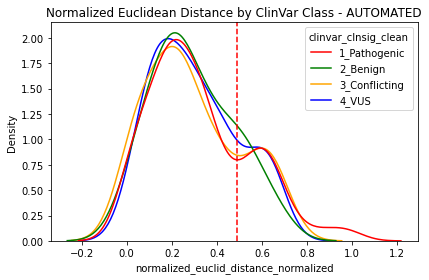

In [34]:
variables = ["normalized_euclid_distance_normalized", "frac_per_0.0", "frac_per_0.2", "cosine_distance"]

# Define color mapping for classes
color_map = {
    "1_Pathogenic": "red",
    "2_Benign": "green",
    "3_Conflicting": "orange",
    "4_VUS": "blue"
}

# Only plot the first variable
var = variables[0]
hue_order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS"]

sns.kdeplot(
    data=scores,
    x=var,
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    palette=[color_map.get(k, "gray") for k in hue_order],
    common_norm=False
)

threshold = 0.49

plt.axvline(x=threshold, color='red', linestyle='--', label='Threshold')

plt.title('Normalized Euclidean Distance by ClinVar Class - AUTOMATED')
plt.tight_layout()
plt.show()

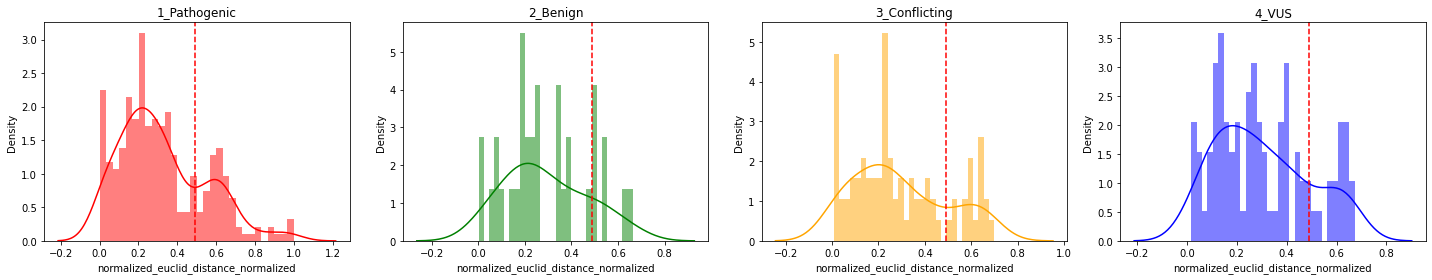

In [35]:
fig, axes = plt.subplots(1, len(hue_order), figsize=(5 * len(hue_order), 4))#, sharey=True)

for ax, class_label in zip(axes, hue_order):
    class_data = scores.filter(pl.col("clinvar_clnsig_clean") == class_label)
    color = color_map.get(class_label, "gray")
    # Histogram
    ax.hist(class_data[var], bins=30, color=color, alpha=0.5, density=True, label="Histogram")
    # Density curve
    sns.kdeplot(class_data[var], color=color, label="Density", ax=ax)
    ax.set_title(f"{class_label}")
    ax.set_xlabel(var)
    ax.set_ylabel("Density")
    ax.axvline(threshold, color="red", linestyle="--", linewidth=1.5)
    # ax.legend()

plt.tight_layout()
plt.show()

In [45]:
num_edge_filter = 1

benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("num_edges") >= num_edge_filter)
print(benign_scores.shape)

path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
print(path_scores.shape)

vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "4_VUS").filter(pl.col("num_edges") >= num_edge_filter)
print(vus_scores.shape)

conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
print(conf_scores.shape)

print(f"With this threshold, we capture {benign_scores.filter(pl.col('normalized_euclid_distance_normalized') > threshold).shape[0]} benign alleles at ~5% error rate, which is {benign_scores.filter(pl.col('normalized_euclid_distance_normalized') > threshold).shape[0] / benign_scores.shape[0] * 100:.2f}% of the benign alleles.")
print(f"With this threshold, we capture {path_scores.filter(pl.col('normalized_euclid_distance_normalized') > threshold).shape[0]} pathogenic alleles at ~5% error rate, which is {path_scores.filter(pl.col('normalized_euclid_distance_normalized') > threshold).shape[0] / path_scores.shape[0] * 100:.2f}% of the pathogenic alleles.")
print(f"With this threshold, we classify {vus_scores.filter(pl.col('normalized_euclid_distance_normalized') > threshold).shape[0]} VUS and {conf_scores.filter(pl.col('normalized_euclid_distance_normalized') > threshold).shape[0]} conflicting alleles as pathogenic at ~5% error rate, which is {vus_scores.filter(pl.col('normalized_euclid_distance_normalized') > threshold).shape[0] / vus_scores.shape[0] * 100:.2f}% and {conf_scores.filter(pl.col('normalized_euclid_distance_normalized') > threshold).shape[0] / conf_scores.shape[0] * 100:.2f}% of the VUS and conflicting alleles, respectively.")


(33, 42)
(281, 42)
(89, 42)
(83, 42)
With this threshold, we capture 6 benign alleles at ~5% error rate, which is 18.18% of the benign alleles.
With this threshold, we capture 66 pathogenic alleles at ~5% error rate, which is 23.49% of the pathogenic alleles.
With this threshold, we classify 17 VUS and 18 conflicting alleles as pathogenic at ~5% error rate, which is 19.10% and 21.69% of the VUS and conflicting alleles, respectively.


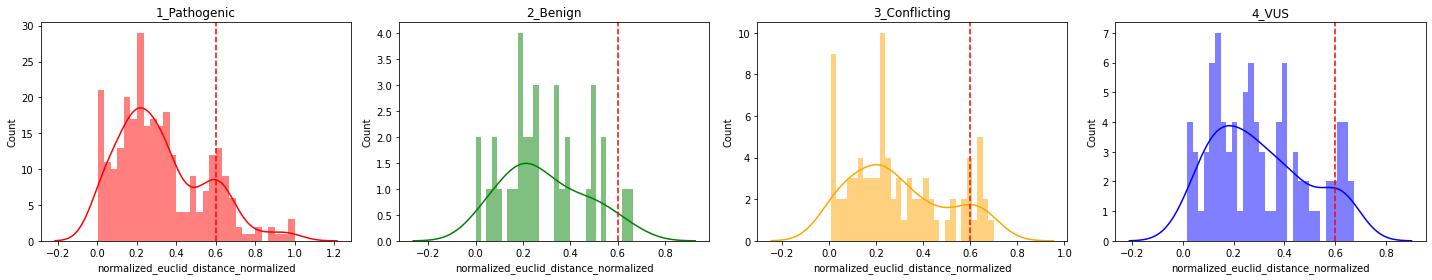

In [37]:
fig, axes = plt.subplots(1, len(hue_order), figsize=(5 * len(hue_order), 4))

for ax, class_label in zip(axes, hue_order):
    class_data = scores.filter(pl.col("clinvar_clnsig_clean") == class_label)
    values = class_data[var]
    color = color_map.get(class_label, "gray")
    
    # Histogram (counts)
    counts, bins, patches = ax.hist(values, bins=30, color=color, alpha=0.5, density=False, label="Histogram")
    
    # KDE scaled to match histogram counts
    kde = sns.kdeplot(values, bw_adjust=1, ax=ax, color=color, label="KDE")
    kde_line = kde.get_lines()[-1]
    x_kde, y_kde = kde_line.get_data()
    
    # Scale KDE y-values to match histogram height
    y_kde_scaled = y_kde * (len(values) * np.diff(bins)[0])
    ax.lines[-1].set_ydata(y_kde_scaled)

    ax.set_title(f"{class_label}")
    ax.set_xlabel(var)
    ax.set_ylabel("Count")
    ax.axvline(0.6, color="red", linestyle="--", linewidth=1.5)
    # ax.legend()  # optional

plt.tight_layout()
plt.show()


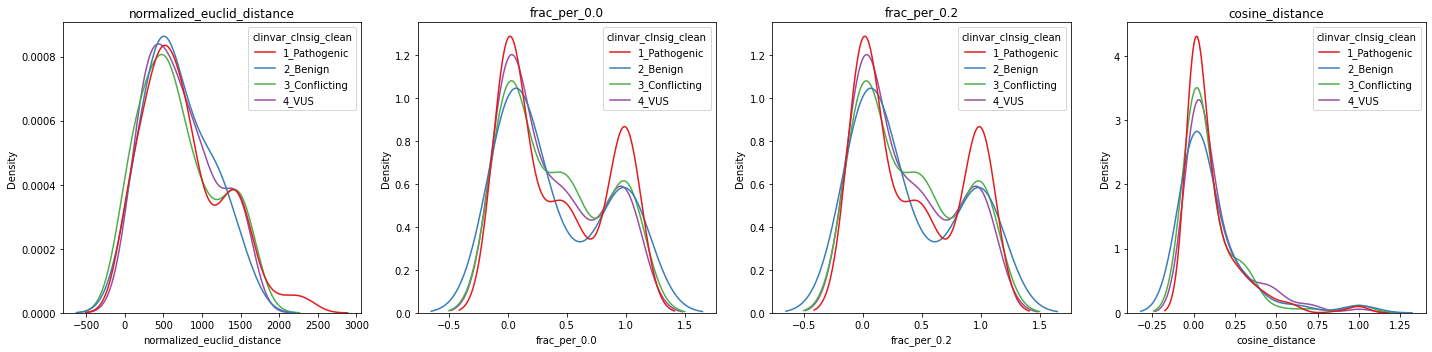

In [38]:
# Define variables to plot
variables = ["normalized_euclid_distance", "frac_per_0.0", "frac_per_0.2", "cosine_distance"]
num_vars = len(variables)

# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(1, num_vars, figsize=(num_vars*5, 5)) ## , sharey=True
hue_order = sorted(scores["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# Loop through variables and create subplots
for ax, var in zip(axes, variables):
    sns.kdeplot(
        data=scores,
        x=var,
        hue="clinvar_clnsig_clean",
        hue_order=hue_order,
        ax=ax,
        palette="Set1",
        common_norm=False
    )
    ax.set_title(var)
plt.tight_layout()
plt.show()

(486, 41)
(163, 41)


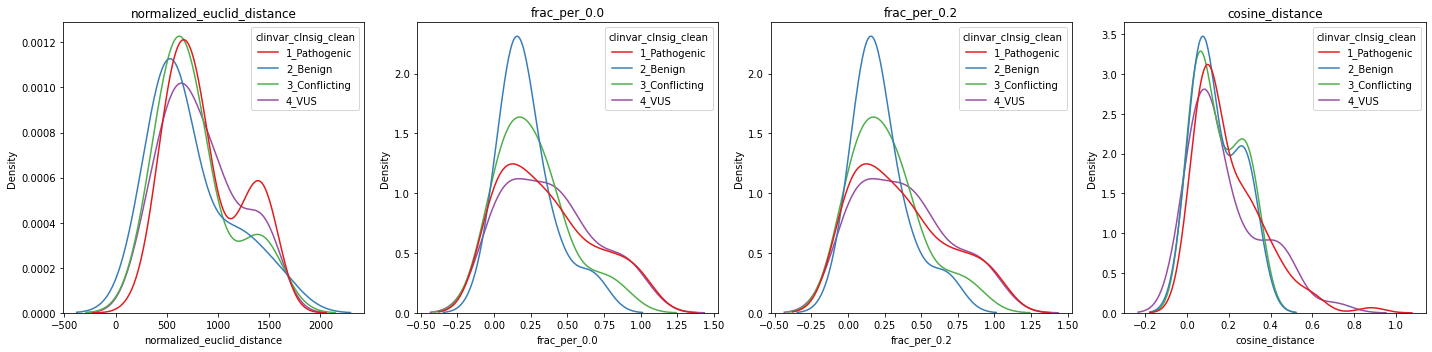

In [39]:
print(scores.shape)
scores_filt = scores.filter(pl.col("num_edges") >= 5)
print(scores_filt.shape)

# Define variables to plot
num_vars = len(variables)

# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(1, num_vars, figsize=(num_vars*5, 5)) ## , sharey=True
hue_order = sorted(scores_filt["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# Loop through variables and create subplots
for ax, var in zip(axes, variables):
    sns.kdeplot(
        data=scores_filt,
        x=var,
        hue="clinvar_clnsig_clean",
        hue_order=hue_order,
        ax=ax,
        palette="Set1",
        common_norm=False
    )
    ax.set_title(var)
plt.tight_layout()
plt.show()

(486, 41)
(74, 41)


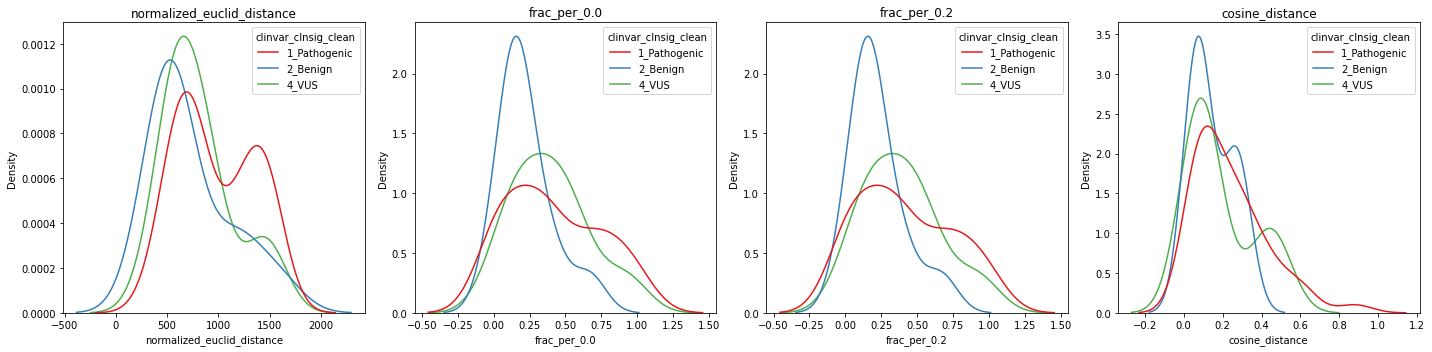

In [40]:
print(scores.shape)
scores_filt = scores.filter(pl.col("num_edges") >= 5).filter(pl.col("StarStatus") >= 2)
print(scores_filt.shape)

# Define variables to plot
num_vars = len(variables)

# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(1, num_vars, figsize=(num_vars*5, 5)) ## , sharey=True
hue_order = sorted(scores_filt["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# Loop through variables and create subplots
for ax, var in zip(axes, variables):
    sns.kdeplot(
        data=scores_filt,
        x=var,
        hue="clinvar_clnsig_clean",
        hue_order=hue_order,
        ax=ax,
        palette="Set1",
        common_norm=False
    )
    ax.set_title(var)
plt.tight_layout()
plt.show()

## Calculate number of conflicting/VUS that could be reclassified

The normalized scores show good separation. How many alleles would this enable us to putatively reclassify?

(33, 41)
(281, 41)
(89, 41)
(83, 41)


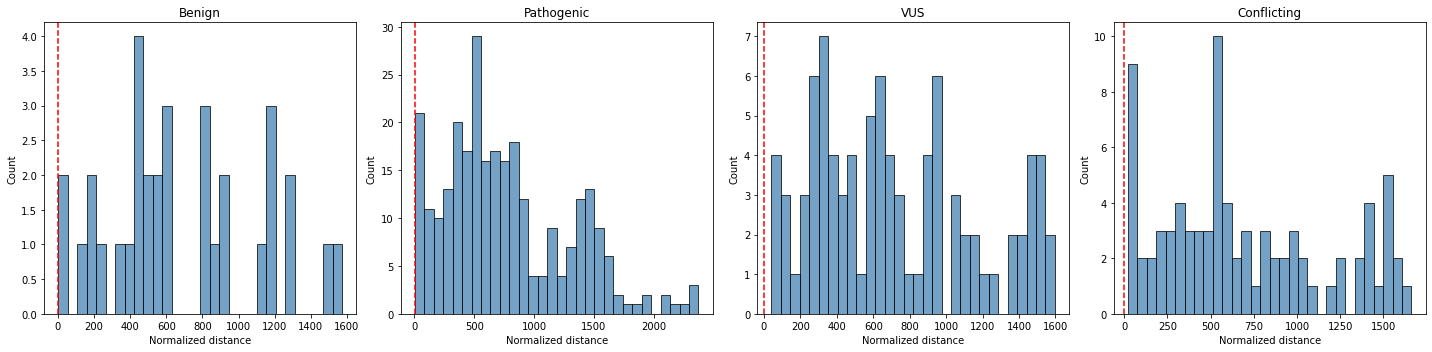

With this threshold, we classify 89 VUS and 83 conflicting alleles as pathogenic at ~5% error rate.


In [41]:
num_edge_filter = 1

benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("num_edges") >= num_edge_filter)
print(benign_scores.shape)

path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
print(path_scores.shape)

vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "4_VUS").filter(pl.col("num_edges") >= num_edge_filter)
print(vus_scores.shape)

conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
print(conf_scores.shape)

# Setup subplots
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
plot_data = [
    ("Benign", benign_scores, axs[0]),
    ("Pathogenic", path_scores, axs[1]),
    ("VUS", vus_scores, axs[2]),
    ("Conflicting", conf_scores, axs[3]),
]

# Plot each group
for title, data, ax in plot_data:
    sns.histplot(data=data, x="normalized_euclid_distance", bins=30, color="steelblue", kde=False, ax=ax)
    ax.axvline(0.6, color="red", linestyle="--", linewidth=1.5)
    ax.set_title(title)
    ax.set_xlabel("Normalized distance")
    ax.set_ylabel("Count")
    ax.grid(False)

plt.tight_layout()
plt.show()

print(f"With this threshold, we classify {vus_scores.filter(pl.col('normalized_euclid_distance') > 0.6).shape[0]} VUS and {conf_scores.filter(pl.col('normalized_euclid_distance') > 0.6).shape[0]} conflicting alleles as pathogenic at ~5% error rate.")

# This is ~13.4% of VUS/conflicting

## Consider gnomAD frequency

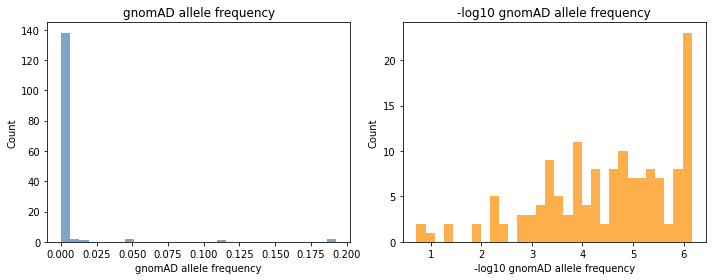

In [42]:
x = scores['gnomad_af']
x = x.filter(x > 0)

y = -np.log10(x.to_numpy())

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].hist(x, bins=30, color='steelblue', alpha=0.7)
axs[0].set_title("gnomAD allele frequency")
axs[0].set_xlabel("gnomAD allele frequency")
axs[0].set_ylabel("Count")

axs[1].hist(y, bins=30, color='darkorange', alpha=0.7)
axs[1].set_title("-log10 gnomAD allele frequency")
axs[1].set_xlabel("-log10 gnomAD allele frequency")
axs[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

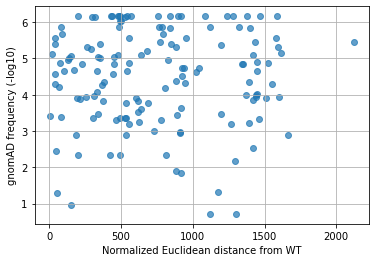

In [43]:
scores = scores.with_columns(
    (-1*pl.col("gnomad_af").log10()).alias("nlog10_gnomad_af")
)

plt.scatter(scores['normalized_euclid_distance'], scores['nlog10_gnomad_af'], alpha=0.7)
plt.ylabel('gnomAD frequency (-log10)')
plt.xlabel('Normalized Euclidean distance from WT')
plt.grid(True)
plt.show()

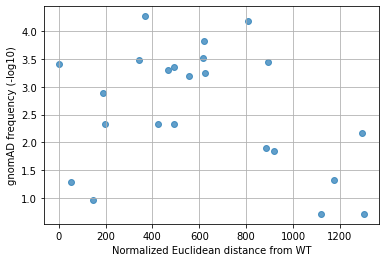

In [44]:
scores_benign = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign")

plt.scatter(scores_benign['normalized_euclid_distance'], scores_benign['nlog10_gnomad_af'], alpha=0.7)
plt.ylabel('gnomAD frequency (-log10)')
plt.xlabel('Normalized Euclidean distance from WT')
plt.grid(True)
plt.show()